In [1]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [31]:
year = 2019
validation_sample_paths_2019 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid.shp',#124
    #f'G:\ICESat-2\Region4_map\Region4b_map\A{year}\A_Region4b_30m_{year}_new10_valid.shp',#124
    f'G:\ICESat-2\Region4_map\Morecambe_map\A2019\A_Morecambe_30m_2019_new10_valid.shp' 
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2020
validation_sample_paths_2020 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662
    # f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',#6424
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2021
validation_sample_paths_2021 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',#6424
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]


year = 2022
validation_sample_paths_2022 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',#6424
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2023
validation_sample_paths_2023 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',#6424
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid.shp',
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2024
validation_sample_paths_2024 = [

    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #1701
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662

]
# 读取并提取指定列
# year = 2019
# gdf_list = []
# for path in validation_sample_paths_2019:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)


gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_ICESat = pd.concat(gdf_list, ignore_index=True)

In [ ]:
# 所有路径放入列表中
year = 2019
validation_sample_paths_2019 = [
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2020
validation_sample_paths_2020 = [
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_sample_points_final.shp',
    f"G:\ICESat-2\Region3_map\Region3c_map\A2020\Region3c_2020_sample_points_final.shp",
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2021
validation_sample_paths_2021 = [
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Araw_map\A2021\Araw_2021_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp',
    f"G:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points_final.shp",
]

year = 2022
validation_sample_paths_2022 = [
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Baglan_map\A2022\Baglan_2022_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\AfonDyfi_map\A2022\AfonDyfi_2022_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
    f"G:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points.shp",
    f"G:\ICESat-2\Region5_map\Carmarthen_map\A2022\Carmarthen_2022_sample_points_final.shp",
    
]

year = 2023
validation_sample_paths_2023 = [
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_sample_points_final.shp',
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
]

year = 2024
validation_sample_paths_2024 = [

    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    
]


# 读取并提取指定列
# gdf_list = []
# for path in validation_sample_paths_2019:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)

gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_DEM = pd.concat(gdf_list, ignore_index=True)

In [29]:
value_list = [i * 1 for i in range(-5, 5)]
print(value_list)

[-5, -4, -3, -2, -1, 0, 1, 2, 3, 4]


In [284]:
value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] !=6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))
print('ICESat-2:')
ICESat_RMSE_list = []
ICESat_MAE_list = []
for v in value_list:

    
    k = z[(z['Ref_dem'] < v+1) &(z['Ref_dem'] > v)]
    x = np.array(k['Ref_dem']) #y_true
    y = np.array(k['OH']) #
    num = len(k)
    ICESat_RMSE = np.sqrt(np.mean((y-x)**2))
    ICESat_RMSE_list.append(ICESat_RMSE)
    ICESat_MAE = np.mean(np.abs(y-x))
    ICESat_MAE_list.append(ICESat_MAE)
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:, {ICESat_RMSE:.4f}')
    print(f'---num: {num}',f'range: [{v}, {v+1}], MAE:, {ICESat_MAE:.4f}')

47874
ICESat-2:
num: 134 range: [-4, -3], RMSE:, 1.2129
---num: 134 range: [-4, -3], MAE:, 0.8033
num: 438 range: [-3, -2], RMSE:, 1.2712
---num: 438 range: [-3, -2], MAE:, 0.8374
num: 2707 range: [-2, -1], RMSE:, 0.7817
---num: 2707 range: [-2, -1], MAE:, 0.3985
num: 7293 range: [-1, 0], RMSE:, 0.4631
---num: 7293 range: [-1, 0], MAE:, 0.2144
num: 10174 range: [0, 1], RMSE:, 0.3453
---num: 10174 range: [0, 1], MAE:, 0.1615
num: 9694 range: [1, 2], RMSE:, 0.2807
---num: 9694 range: [1, 2], MAE:, 0.1474
num: 9801 range: [2, 3], RMSE:, 0.3893
---num: 9801 range: [2, 3], MAE:, 0.2251
num: 6191 range: [3, 4], RMSE:, 0.3601
---num: 6191 range: [3, 4], MAE:, 0.1818
num: 1344 range: [4, 5], RMSE:, 0.4292
---num: 1344 range: [4, 5], MAE:, 0.2419
num: 0 range: [5, 6], RMSE:, nan
---num: 0 range: [5, 6], MAE:, nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [280]:
value_list = [-4, -3.5, -3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5,  4, 4.5, 5]

z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] !=6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))
print('ICESat-2:')
ICESat_RMSE_list = []
ICESat_MAE_list = []
for v in value_list:

    
    k = z[(z['Ref_dem'] < v+0.5) &(z['Ref_dem'] > v)]
    x = np.array(k['Ref_dem']) #y_true
    y = np.array(k['OH']) #
    num = len(k)
    ICESat_RMSE = np.sqrt(np.mean((y-x)**2))
    ICESat_RMSE_list.append(ICESat_RMSE)
    ICESat_MAE = np.mean(np.abs(y-x))
    ICESat_MAE_list.append(ICESat_MAE)
    print(f'num: {num}',f'range: [{v}, {v+0.5}], RMSE:, {ICESat_RMSE:.4f}')

47874
ICESat-2:
num: 54 range: [-4, -3.5], RMSE:, 1.3290
num: 80 range: [-3.5, -3.0], RMSE:, 1.1277
num: 149 range: [-3, -2.5], RMSE:, 1.5791
num: 289 range: [-2.5, -2.0], RMSE:, 1.0787
num: 805 range: [-2, -1.5], RMSE:, 0.9208
num: 1900 range: [-1.5, -1.0], RMSE:, 0.7150
num: 3120 range: [-1, -0.5], RMSE:, 0.4932
num: 4167 range: [-0.5, 0.0], RMSE:, 0.4374
num: 4557 range: [0, 0.5], RMSE:, 0.3576
num: 5603 range: [0.5, 1.0], RMSE:, 0.3353
num: 5165 range: [1, 1.5], RMSE:, 0.2810
num: 4509 range: [1.5, 2.0], RMSE:, 0.2806
num: 5280 range: [2, 2.5], RMSE:, 0.3527
num: 4509 range: [2.5, 3.0], RMSE:, 0.4286
num: 4196 range: [3, 3.5], RMSE:, 0.3479
num: 1985 range: [3.5, 4.0], RMSE:, 0.3855
num: 1093 range: [4, 4.5], RMSE:, 0.4480
num: 250 range: [4.5, 5.0], RMSE:, 0.3355
num: 0 range: [5, 5.5], RMSE:, nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [282]:
value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
z = merged_gdf_DEM.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
print(len(z))
print('Retrival DEM:')
DEM_RMSE_list = []
DEM_MAE_list= []
for v in value_list:

    
    k = z[(z['Refer_dem'] < v+1) &(z['Refer_dem'] > v)]
    x = np.array(k['Refer_dem']) #y_true
    y = np.array(k['DEM_new9']) #
    DEM_RMSE = np.sqrt(np.mean((y-x)**2))
    DEM_MAE = np.mean(np.abs(y-x))
    DEM_MAE_list.append(DEM_MAE)
    num = len(k)
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:, {DEM_RMSE:.4f}')
    DEM_RMSE_list.append(DEM_RMSE)

102054
Retrival DEM:
num: 617 range: [-4, -3], RMSE:, 1.7755
num: 3745 range: [-3, -2], RMSE:, 1.5690
num: 16266 range: [-2, -1], RMSE:, 0.8986
num: 23253 range: [-1, 0], RMSE:, 0.5881
num: 20349 range: [0, 1], RMSE:, 0.4752
num: 16145 range: [1, 2], RMSE:, 0.4610
num: 11726 range: [2, 3], RMSE:, 0.4969
num: 8255 range: [3, 4], RMSE:, 0.4576
num: 1479 range: [4, 5], RMSE:, 0.6868
num: 0 range: [5, 6], RMSE:, nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [278]:
z = merged_gdf_DEM.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
print(len(z))
print('Retrival DEM:')
DEM_RMSE_list = []
DEM_MAE_list= []
for v in value_list:

    
    k = z[(z['Refer_dem'] < v+1) &(z['Refer_dem'] > v)]
    x = np.array(k['Refer_dem']) #y_true
    y = np.array(k['DEM_new9']) #
    DEM_RMSE = np.sqrt(np.mean((y-x)**2))
    DEM_MAE = np.mean(np.abs(y-x))
    DEM_MAE_list.append(DEM_MAE)
    num = len(k)
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:, {DEM_RMSE:.4f}')
    DEM_RMSE_list.append(DEM_RMSE)

102054
Retrival DEM:
num: 617 range: [-4, -3], RMSE:, 1.7755
num: 1128 range: [-3.5, -2.5], RMSE:, 1.9136
num: 3745 range: [-3, -2], RMSE:, 1.5690
num: 9044 range: [-2.5, -1.5], RMSE:, 1.2082
num: 16266 range: [-2, -1], RMSE:, 0.8986
num: 22262 range: [-1.5, -0.5], RMSE:, 0.6979
num: 23253 range: [-1, 0], RMSE:, 0.5881
num: 21926 range: [-0.5, 0.5], RMSE:, 0.5188
num: 20349 range: [0, 1], RMSE:, 0.4752
num: 18205 range: [0.5, 1.5], RMSE:, 0.4703
num: 16145 range: [1, 2], RMSE:, 0.4610
num: 14147 range: [1.5, 2.5], RMSE:, 0.4533
num: 11726 range: [2, 3], RMSE:, 0.4969
num: 10065 range: [2.5, 3.5], RMSE:, 0.5193
num: 8255 range: [3, 4], RMSE:, 0.4576
num: 4612 range: [3.5, 4.5], RMSE:, 0.4617
num: 1479 range: [4, 5], RMSE:, 0.6868
num: 197 range: [4.5, 5.5], RMSE:, 1.0051
num: 0 range: [5, 6], RMSE:, nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [230]:
DEM_RMSE_list

[1.7755322829960565,
 1.9136326755684543,
 1.5690405953836108,
 1.208244957909201,
 0.8985767768586378,
 0.6978618948686308,
 0.5881297824756836,
 0.5187676191169515,
 0.47520252658702594,
 0.4702877332415091,
 0.46103432510646253,
 0.45327892850554047,
 0.4969297669371895,
 0.5193396144249958,
 0.45756114543949744,
 0.46171957178492423,
 0.6867648523376823,
 1.0050990691433532,
 nan]

ValueError: Input contains NaN.

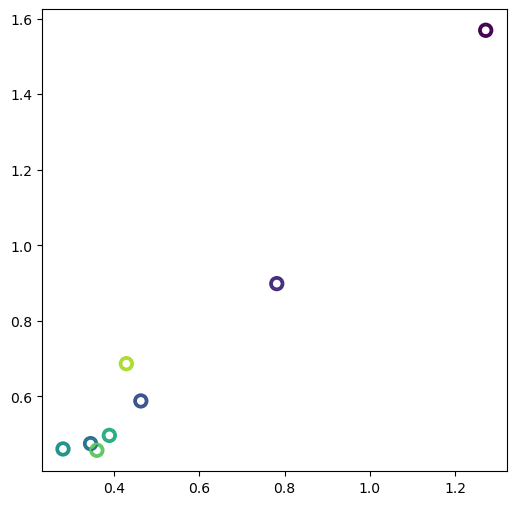

: 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 数据
# DEM_RMSE_list = [1.7755, 1.5690, 0.8985, 0.5881, 0.4752, 0.4610, 0.4969, 0.4575, 0.686]
# ICESat_RMSE_list = [1.2128, 1.2719, 0.8220, 0.47894, 0.3537, 0.28394, 0.3881, 0.3600, 0.429198]

x = np.array(ICESat_RMSE_list[1:18])
y = np.array(DEM_RMSE_list[1:18])

# 渐变颜色
colors = plt.cm.viridis(np.linspace(0, 1, len(x)))

plt.figure(figsize=(6, 6))

# 空心圆点
plt.scatter(x, y, facecolors='none', edgecolors=colors, s=50, marker="o", linewidths=1.5)

#给每个点加序号标注（1–9）
str_list = ['[-4,-3]','[-3,-2]','[-2,-1]','[-1,-0]','[0,1]','[1,2]','[2,3]','[3,4]','[4,5]',]
# str_list = ['[-4,-3.5]','[-3.5,-3]','[-3,-2.5]','[-2.5,-2]','[-2,-1.5]','[-1.5,-1]','[-1,-0.5]',
#             '[-0.5,0]','[0,0.5]','[0.5,1]','[1,1.5]','[1.5,2]','[2,2.5]','[2.5,3]','[3,3.5]','[3.5,4]','[4,4.5]']
# for i, (xx, yy) in enumerate(zip(x, y)):
#     plt.text(xx + 0.05, yy + 0.05, str_list[i], fontsize=9, color="black")


# for i, (xx, yy) in enumerate(zip(x, y)):
#     if i % 2 == 0:
#         dx, dy = 0.03, 0.03   # 偶数点标注在右上
#     else:
#         dx, dy = -0.03, -0.03 # 奇数点标注在左下
#     plt.text(xx + dx, yy + dy, str_list[i], fontsize=9, color="black",
#              bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1))
for i, (xx, yy) in enumerate(zip(x, y)):
    plt.scatter(xx, yy, facecolors='none', edgecolors=[colors[i]], s=90, marker="o", linewidths=1.5,
                label=f"{str_list[i]}")

xlim = plt.xlim()
ylim = plt.ylim()

y_pred = poly1d_fn(x)
r2 = r2_score(y, y_pred)

# 在拟合线附近标注公式和 R²
text_x = 0.6 * (xlim[0] + xlim[1])   # 大约在坐标轴中间
text_y = poly1d_fn(text_x)
plt.text(text_x, text_y, f"y = {coef[0]:.2f}x + {coef[1]:.2f}\nR² = {r2:.2f}",
         color="black", fontsize=10, ha="left", va="bottom",
         bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=20))


# 获取当前坐标轴范围
xlim = [0, 2]#plt.xlim()
ylim = [0, 2]#plt.ylim()

# 1:1 参考线（灰色虚线）
min_val = min(xlim[0], ylim[0])
max_val = max(xlim[1], ylim[1])
plt.plot([min_val, max_val], [min_val, max_val], '--', color='gray', linewidth=1)

# 线性拟合（红色实线）
coef = np.polyfit(x, y, 1)
poly1d_fn = np.poly1d(coef)
xx = np.linspace(xlim[0], xlim[1], 100)
plt.plot(xx, poly1d_fn(xx), '--',color = 'blue', linewidth=1.5)

# 恢复坐标轴范围（避免被拟合线改变）
plt.xlim(xlim)
plt.ylim(ylim)

plt.xlabel("Refined ICESat-2 RMSE", fontsize = 12)
plt.ylabel("Retrieved DEM RMSE", fontsize = 12)
plt.title("RMSE Scatter plot")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


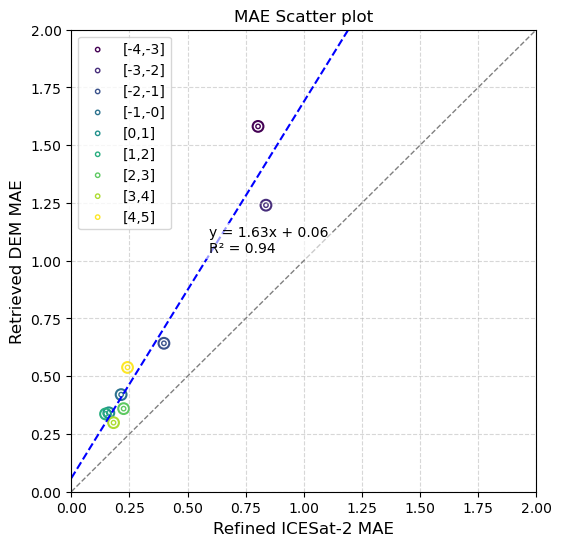

In [290]:
import matplotlib.pyplot as plt
import numpy as np

# 数据
# DEM_RMSE_list = [1.7755, 1.5690, 0.8985, 0.5881, 0.4752, 0.4610, 0.4969, 0.4575, 0.686]
# ICESat_RMSE_list = [1.2128, 1.2719, 0.8220, 0.47894, 0.3537, 0.28394, 0.3881, 0.3600, 0.429198]

x = np.array(ICESat_MAE_list[:9])
y = np.array(DEM_MAE_list[:9])

# 渐变颜色
colors = plt.cm.viridis(np.linspace(0, 1, len(x)))

plt.figure(figsize=(6, 6))

# 空心圆点
plt.scatter(x, y, facecolors='none', edgecolors=colors, s=60, marker="o", linewidths=1.5)

#给每个点加序号标注（1–9）
str_list = ['[-4,-3]','[-3,-2]','[-2,-1]','[-1,-0]','[0,1]','[1,2]','[2,3]','[3,4]','[4,5]',]
# for i, (xx, yy) in enumerate(zip(x, y)):
#     plt.text(xx + 0.05, yy + 0.05, str_list[i], fontsize=9, color="black")


# for i, (xx, yy) in enumerate(zip(x, y)):
#     if i % 2 == 0:
#         dx, dy = 0.03, 0.03   # 偶数点标注在右上
#     else:
#         dx, dy = -0.03, -0.03 # 奇数点标注在左下
#     plt.text(xx + dx, yy + dy, str_list[i], fontsize=9, color="black",
#              bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1))
for i, (xx, yy) in enumerate(zip(x, y)):
    plt.scatter(xx, yy, facecolors='none', edgecolors=[colors[i]], s=10, marker="o", linewidths=1,
                label=f"{str_list[i]}")
    
xlim = plt.xlim()
ylim = plt.ylim()

y_pred = poly1d_fn(x)
r2 = r2_score(y, y_pred)

# 在拟合线附近标注公式和 R²
text_x = 0.6 * (xlim[0] + xlim[1])   # 大约在坐标轴中间
text_y = poly1d_fn(text_x)
plt.text(text_x, text_y, f"y = {coef[0]:.2f}x + {coef[1]:.2f}\nR² = {r2:.2f}",
         color="black", fontsize=10, ha="left", va="bottom",
         bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=2))


# 获取当前坐标轴范围
xlim = [0, 2]#plt.xlim()
ylim = [0, 2]#plt.ylim()

# 1:1 参考线（灰色虚线）
min_val = min(xlim[0], ylim[0])
max_val = max(xlim[1], ylim[1])
plt.plot([min_val, max_val], [min_val, max_val], '--', color='gray', linewidth=1)

# 线性拟合（红色实线）
coef = np.polyfit(x, y, 1)
poly1d_fn = np.poly1d(coef)
xx = np.linspace(xlim[0], xlim[1], 100)
plt.plot(xx, poly1d_fn(xx), '--',color='blue', linewidth=1.5)

# 恢复坐标轴范围（避免被拟合线改变）
plt.xlim(xlim)
plt.ylim(ylim)

plt.xlabel("Refined ICESat-2 MAE", fontsize = 12)
plt.ylabel("Retrieved DEM MAE", fontsize = 12)
plt.title("MAE Scatter plot")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [ ]:
import matplotlib.pyplot as plt

# 假设 merged_gdf_DEM 是一维数据，例如 pandas.Series 或 numpy.array
# merged_gdf_DEM = ...

# 自定义分箱边界
bins = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

plt.figure(figsize=(7,5))
colors = plt.cm.viridis(np.linspace(0, 1, len(x)))
plt.hist(merged_gdf_DEM['Refer_dem'], ,bins=bins, edgecolor='black', alpha=0.7)

plt.xlabel("DEM Value")
plt.ylabel("Frequency")
plt.title("Histogram with Custom Bins")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


102054


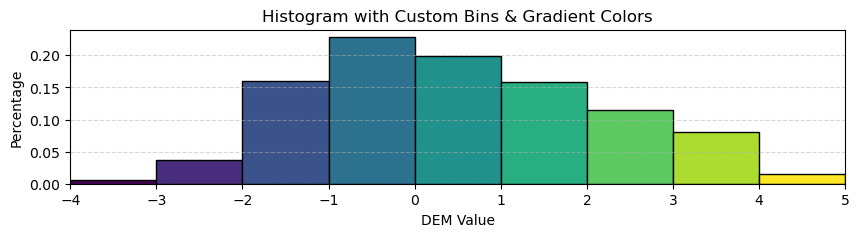

In [242]:
import matplotlib.pyplot as plt
import numpy as np

# 假设 merged_gdf_DEM 已经是一维
z = merged_gdf_DEM.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
print(len(z))
values = z['Refer_dem']

# 自定义 bins
bins = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
# bins = [-4, -3.5, -3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5,  4, 4.5, 5]
plt.figure(figsize=(10,2))
# 计算直方图数据
# counts, edges, patches = plt.hist(values, bins=bins, edgecolor="black")

# 画直方图 (density=True 转换为概率密度)
counts, edges, patches = plt.hist(values, bins=bins, edgecolor="black", density=True)

# 转换为百分比（每个 bin 的概率 × bin 宽度 × 100）
bin_widths = np.diff(edges)
percentages = counts * bin_widths * 100

# 按 bin 个数生成渐变颜色
colors = plt.cm.viridis(np.linspace(0, 1, len(patches)))
plt.xlim([-4,5])
# 给每个柱子上色
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

plt.xlabel("DEM Value")
plt.ylabel("Percentage")
plt.title("Histogram with Custom Bins & Gradient Colors")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


47874


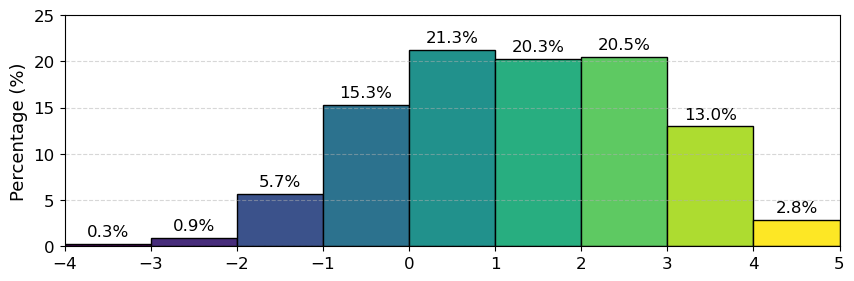

In [277]:
import matplotlib.pyplot as plt
import numpy as np

z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] !=6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))

values = z['Ref_dem']
bins = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
# bins = [-4, -3.5, -3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5,  4, 4.5, 5]
plt.figure(figsize=(10,3))
# # 计算直方图数据
# counts, edges, patches = plt.hist(values, bins=bins, edgecolor="black")
weights = np.ones_like(values) / len(values) * 100  

# 计算百分比权重
weights = np.ones_like(values) / len(values) * 100  

# 画直方图（每个 bin 的高度就是百分比）
counts, edges, patches = plt.hist(values, bins=bins, edgecolor="black", weights=weights)

percentages = counts * bin_widths * 100
# 按 bin 个数生成渐变颜色
colors = plt.cm.viridis(np.linspace(0, 1, len(patches)))
plt.ylim([0, 25])
plt.xlim([-4,5])

# 在柱子上标注百分比（保留 1 位小数）
bin_centers = 0.5 * (edges[:-1] + edges[1:])
for count, x in zip(counts, bin_centers):
    plt.text(x, count + 0.5, f"{count:.1f}%", ha="center", va="bottom", fontsize=12)

# 给每个柱子上色
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

plt.tick_params(axis='both', which='major', labelsize=12)
# plt.xlabel("DEM Value")
plt.ylabel("Percentage (%)", fontsize = 13)
# plt.title("Histogram with Custom Bins & Percentages")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

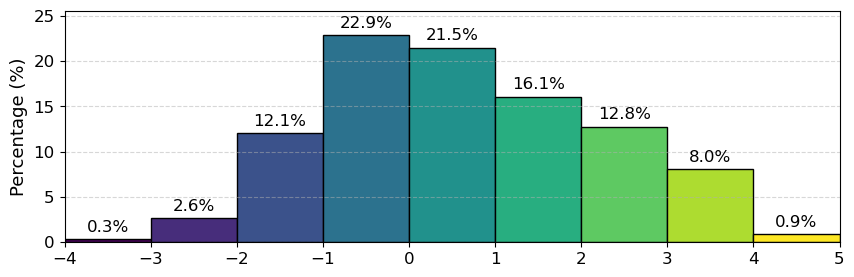

In [271]:
import matplotlib.pyplot as plt
import numpy as np

# 假设 merged_gdf_DEM 已经是一维
values = merged_gdf_DEM.values.ravel()
plt.figure(figsize=(10,3))
# 自定义 bins
bins = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

# 计算百分比权重
weights = np.ones_like(values) / len(values) * 100  

# 画直方图（每个 bin 的高度就是百分比）
counts, edges, patches = plt.hist(values, bins=bins, edgecolor="black", weights=weights)

# 设置颜色（渐变）
colors = plt.cm.viridis(np.linspace(0, 1, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)
plt.ylim([0,25.5])
plt.xlim([-4,5])
# 在柱子上标注百分比（保留 1 位小数）
bin_centers = 0.5 * (edges[:-1] + edges[1:])
for count, x in zip(counts, bin_centers):
    plt.text(x, count + 0.5, f"{count:.1f}%", ha="center", va="bottom", fontsize=12)

plt.tick_params(axis='both', which='major', labelsize=12)
# plt.xlabel("DEM Value")
plt.ylabel("Percentage (%)", fontsize = 13)
# plt.title("Histogram with Custom Bins & Percentages")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()
